---
title: Using Xsuite for a simple FODO 
author:
  - name: G. Sterbini
    affiliations:
    - CERN, Geneva, Switzerland
keywords:
    - FODO
    - Xsuite
    - particle tracking
    - twiss parameters
    - linear map
    - symplectic matrix
exports:
  - format: pdf
    template: aap_cas
    output: test
abstract: This is a pdf-version of the basic python notebook we used during the course to introduce and explore the potential of the Xsuite code for linear optics computation. Emphasis is put on the coding aspect and to be used as complement for the lecture on linear optics design.
bibliography:
  - main.bib
---

# Introduction
In this document, we present some basic numerical approach on lattice design, using [Xsuite](https://xsuite.readthedocs.io/en/latest/index.html). Xsuite is a collection python packages for the simulation of the beam dynamics in particle accelerators. It supports different computing platforms, in particular conventional CPUs and and Graphic Processing Units (GPUs).
Please refer to the [Xsuite](https://xsuite.readthedocs.io/en/latest/index.html) manual to install it.

This document is produced from a python Jupyter nootebook using [MyST](https://doi.org/10.5281/ZENODO.14805610).

[![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.14805610.svg)](https://doi.org/10.5281/zenodo.14805610)

As a first step we can import the `xtract` module containing the relevant numerical methods we will use.

In [75]:
import xtrack as xt

# A simple optics line

We can use the `Environment` class as a container where to store the parameters, elements, sequences we would like to study.

In [76]:
# Create an environment
env = xt.Environment()

For example, in the enviroment we can define the variables controlling the properties of the our elements, for example we can define the variable `k1`.

In [77]:
# Define a variable in the environment
env['k1'] = 1

We can then define a list of elements like markers, quadrupoles and drift corresponding to the python classes `Marker`, `Quadrupole` and `Drift` of the `xtrack` module. The `Marker` class has no parameters, while the `Quadrupole` class is instatinated with the property `length` and `k1`, the lenght and normalized gradient, respectively.

In [80]:
# Define a list of components of the lattice
my_components = [
# a marker at the beginning of the lattice
env.new('start', xt.Marker),
# a quadrupole of length of 1 [m] and k1 equal to 1 [1/m^2]
env.new('qf', xt.Quadrupole, length=1, k1='k1'),
# a drift of length of 1 [m]
env.new('drift_1', xt.Drift, length=1),
env.new('qd', xt.Quadrupole, length=1, k1=' -k1', k1s=0.1*0),
env.new('drift_2', xt.Drift, length=1),
# a marker at the end of the lattice
env.new('end', xt.Marker),
]

Then we finally define a line using the `env.new_line` method.

In [81]:
# Build the simplest stable lattice
line = env.new_line(components=my_components)

It is important at this stage to consider a reference particle (momentum and and rest mass) to be used to compute the property of the `line` object around the closed orbit of the reference particle.

In [82]:
# Define reference particle
line.particle_ref = xt.Particles(p0c=7e12, mass0=xt.PROTON_MASS_EV)

## Twiss method and plot

Once we have the line, we can compute its twiss parameters (assuming that the FODO is stable). Since we did not include longitudinal focusing (no RF), the 6-dimensional twiss will not be stable, so we perform only a 4-dimensional twiss, `twiss4d`.

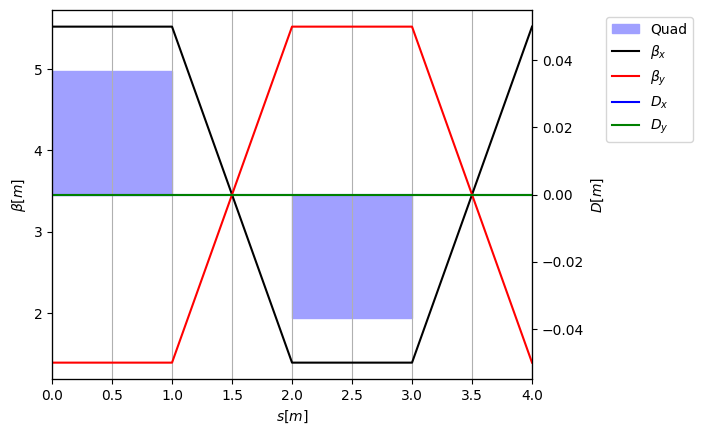

In [84]:
from matplotlib import pyplot as plt
my_twiss = line.twiss4d()
aux = my_twiss.plot();
plt.savefig('images/fodo.pdf')

```{figure} images/test.pdf
:label:fodo.pdf
:alt: Result of the `twiss` of a FODO line.
:align: center

Result of the `line.twiss4d().plot()` method of our FODO line.
```

It is possible to extract the optics function along the line in a tabular way. Here, as example, we show the name of the elements, their longitudinal position and the $\beta$, $\alpha$ and phase advance for each element.

In [85]:
# Look at the twiss results
df = my_twiss.to_pandas()[['name','s','betx','bety','alfx','alfy','mux','muy']]
df.round(3)

,name,s,betx,bety,alfx,alfy,mux,muy
0,start,0.0,5.523,1.389,-2.941,1.194,0.000,0.000
1,qf,0.0,5.523,1.389,-2.941,1.194,0.000,0.000
2,drift_1,1.0,5.523,1.389,2.941,-1.194,0.024,0.161
3,qd,2.0,1.389,5.523,1.194,-2.941,0.083,0.219
4,drift_2,3.0,1.389,5.523,-1.194,2.941,0.244,0.244
5,end,4.0,5.523,1.389,-2.941,1.194,0.303,0.303
6,_end_point,4.0,5.523,1.389,-2.941,1.194,0.303,0.303


It is also possible to extract the linear map between two elements of the line (e.g. the `start` and `end` marker).

In [86]:
import pandas as pd
M_OTM = my_twiss.get_R_matrix(start='start', end='end')
pd.DataFrame(M_OTM).round(3)

,0,1,2,3,4,5
0,-3.106,5.225,0.000,0.000,0.0,0.0
1,-1.652,2.458,0.000,0.000,0.0,0.0
2,0.000,0.000,0.805,1.314,0.0,0.0
3,0.000,0.000,-1.652,-1.454,0.0,0.0
4,0.000,0.000,0.000,0.000,1.0,-0.0
5,0.000,0.000,0.000,0.000,0.0,1.0


These matrices are symplectic and we can verify it this the cell below.

In [87]:
import numpy as np
def is_symplectic(M):
    """Check if the matrix M is symplectic."""
    n = M.shape[0] // 2
    # Construct the symplectic matrix Omega
    my_block = np.array([[0, 1], [-1, 0]])
    omega = np.kron(np.eye(n), my_block)
    return np.allclose(M.T @ omega @ M, omega)

is_symplectic(M_OTM)

True

As a sanity check, we can verify that the linear maps of the single elements corresponds to the known matrices. For a 2D thick focusing quadrupole we have

\begin{equation}
\left(
\begin{array}{cc}
 \cos \left(\sqrt{\text{K1}} L\right) & \frac{\sin \left(\sqrt{\text{K1}} L\right)}{\sqrt{\text{K1}}} \\
 -\sqrt{\text{K1}} \sin \left(\sqrt{\text{K1}} L\right) & \cos \left(\sqrt{\text{K1}} L\right) \\
\end{array}
\right)
\label{eq:focusing_q}
\end{equation}

and the one of a thick defocusing quadrupole

\begin{equation}
\left(
\begin{array}{cc}
 \cosh \left(\sqrt{\text{K1}} L\right) & \frac{\sinh \left(\sqrt{\text{K1}} L\right)}{\sqrt{\text{K1}}} \\
 \sqrt{\text{K1}} \sinh \left(\sqrt{\text{K1}} L\right) & \cosh \left(\sqrt{\text{K1}} L\right) \\
\end{array}
\right).
\label{eq:defocusing_q}
\end{equation}

The numerical 6D matrix of the quadrupole (horizontal focusing) can be extracted with the following syntax.

In [89]:
qf_matrix = my_twiss.get_R_matrix(start='qf', end='drift_1')
pd.DataFrame(qf_matrix).round(3)

,0,1,2,3,4,5
0,0.540,0.841,0.000,0.000,0.0,0.0
1,-0.841,0.540,0.000,0.000,0.0,0.0
2,0.000,0.000,1.543,1.175,0.0,0.0
3,0.000,0.000,1.175,1.543,0.0,0.0
4,0.000,0.000,0.000,0.000,1.0,-0.0
5,0.000,0.000,0.000,0.000,0.0,1.0


The values of the `qf_matrix` can be related to Eqs.~\ref{eq:focusing_q} 

In [90]:
pd.DataFrame([[np.cos(1), np.sin(1)],[-np.sin(1), np.cos(1)]]).round(3)

,0,1
0,0.540,0.841
1,-0.841,0.540


and to Eqs.~\ref{eq:defocusing_q}

In [91]:
pd.DataFrame([[np.cosh(1), np.sinh(1)],[np.sinh(1), np.cosh(1)]]).round(3)

,0,1
0,1.543,1.175
1,1.175,1.543


In [29]:
R = my_twiss.rotation_matrix
pd.DataFrame(R).round(3)

,0,1,2,3,4,5
0,-0.324,0.946,0.000,0.000,0.000,0.000
1,-0.946,-0.324,0.000,0.000,0.000,0.000
2,0.000,0.000,-0.324,0.946,0.000,0.000
3,0.000,0.000,-0.946,-0.324,0.000,0.000
4,0.000,0.000,0.000,0.000,0.951,0.309
5,0.000,0.000,0.000,0.000,-0.309,0.951


In [30]:
P_bar = my_twiss.W_matrix[0]
inv = np.linalg.inv
pd.DataFrame(P_bar@R@inv(P_bar)-M_OTM)

,0,1,2,3,4,5
0,-8.881784e-16,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
1,2.220446e-16,-1.332268e-15,0.000000e+00,0.000000e+00,0.000000,0.000000
2,0.000000e+00,0.000000e+00,8.881784e-16,8.881784e-16,0.000000,0.000000
3,0.000000e+00,0.000000e+00,-6.661338e-16,-8.881784e-16,0.000000,0.000000
4,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-0.048943,0.309017
5,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-0.309017,-0.048943


### Phase advance considerations

Slicing line:   0%|          | 0/6 [00:00<?, ?it/s]

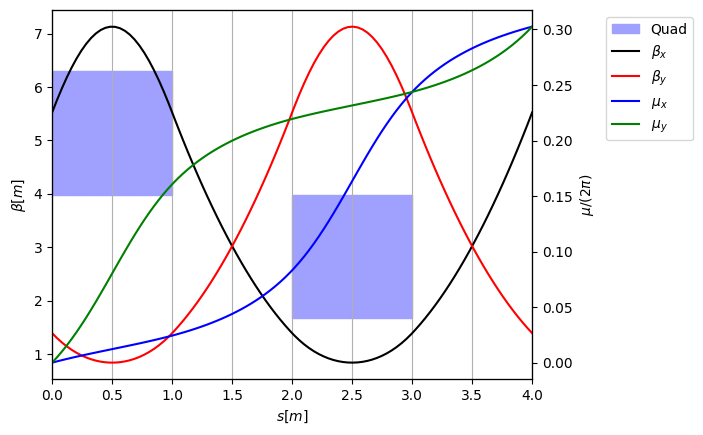

In [31]:
# we added some points to the line
line.cut_at_s(np.linspace(0, 4, 100))
my_twiss = line.twiss4d()
my_twiss.plot(yl = 'betx bety', yr = 'mux muy')
plt.savefig('images/fig2.pdf')

```{figure} images/fig2.pdf
:label: myFigure
:alt: Sunset at the beach
:align: center

An example of evaluating the same lattice at different positions.
```

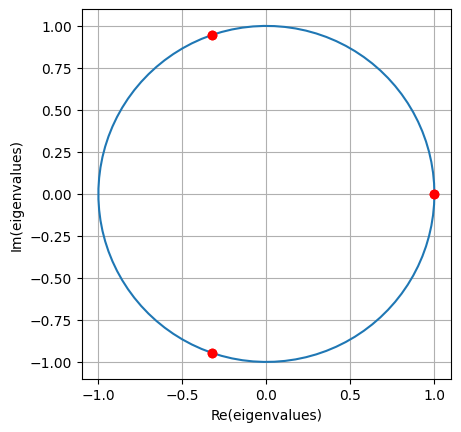

In [32]:
eigs = np.linalg.eigvals(my_twiss.get_R_matrix(start='start', end='end'))
# take the phase advance of the first eigenvector

# plot the circle of radius 1
plt.plot(np.cos(np.linspace(0, 2*np.pi, 100)), np.sin(np.linspace(0, 2*np.pi, 100)))
plt.plot(np.real(eigs), np.imag(eigs), 'or')
plt.axis('square')
plt.grid(True)
plt.xlabel('Re(eigenvalues)')
plt.ylabel('Im(eigenvalues)')
assert np.allclose(np.abs(eigs), 1)

In [40]:
# relation of the phase advance with the eigenvectors
phase_advance = np.angle(eigs[2])
print(phase_advance/(2*np.pi))

0.30254964175929033


### Chromaticity and off-momentum $\beta$-beating

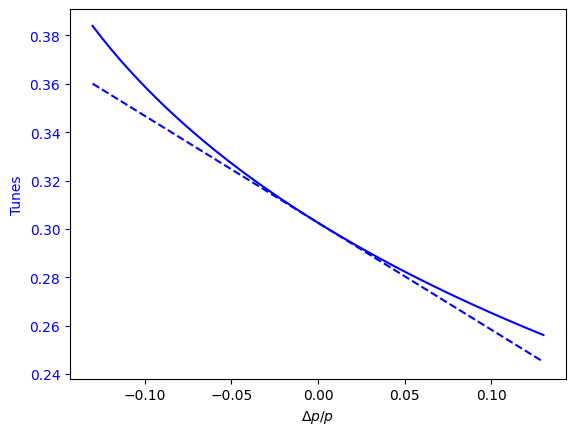

In [46]:
delta_values = np.linspace(-1.3e-1, 1.3e-1, 50)

qx_values = []
qy_values = []
betax1_max = []
betay1_max = []
betax2_max = []
betay2_max = []

for i, delta in enumerate(delta_values):
    print(f'Xsuite working on {i} of {len(delta_values)}  ', end='\r', flush=True)
    tt = line.twiss(method='4d', delta0=delta)

    qx_values.append(tt.qx) 
    qy_values.append(tt.qy) 
    betax1_max.append(np.max(tt.betx1))
    betay1_max.append(np.max(tt.bety1))
    betax2_max.append(np.max(tt.betx2))
    betay2_max.append(np.max(tt.bety2))




plt.plot(delta_values, qx_values, label='qx', color='b')
#plt.plot(delta_values, qy_values, label='qy', color='b', ls=':')

plt.gca().tick_params(axis='y', colors='blue')
plt.ylabel('Tunes', color='blue')
plt.xlabel('$\\Delta p/p$')
plt.plot(delta_values, delta_values*my_twiss.dqx+my_twiss.qx, 'b--')

# plt.twinx()
# plt.plot(delta_values, betax1_max, label='$\\beta_{x1, max}$', color='r')
# plt.plot(delta_values, betay1_max, label='$\\beta_{y1, max}$', color='r', ls=':')
# plt.plot(delta_values, betax2_max, label='$\\beta_{x2, max}$', color='r', ls='--')
# plt.plot(delta_values, betay2_max, label='$\\beta_{y2, max}$', color='r', ls='--')


# # set in red the y axis and its ticks
# plt.gca().spines['right'].set_color('red')
# plt.gca().tick_params(axis='y', colors='red')
# plt.gca().spines['left'].set_color('blue')

# plt.ylabel('$\\beta_{max}$ [m]', color='red')
# plt.grid(True)
# plot the line with slope my_twiss.qx


In [25]:
print(f'Qx = {my_twiss.qx}')
print(f'Qy = {my_twiss.qy}')

print(f'DQx (x-chromaticity) = {my_twiss.dqx}')
print(f'DQy (y-chromaticity) = {my_twiss.dqy}')

Qx = 0.3025496417592902
Qy = 0.30254964175929067
DQx (x-chromaticity) = -0.44251119710181364
DQy (y-chromaticity) = -0.44251119709293185


### Tracking particles and volume preservation in linear optics

In [26]:
env['k1'] = 1

# Remeber that the volume of the hyper-cube of the n vecotor is R^n
# is the determinant of their matrix

particles = line.build_particles(
                        x =  [1, 0, 0, 0, 0, 0],
                        px = [0, 1, 0, 0, 0, 0],
                        y =  [0, 0, 1, 0, 0, 0],
                        py = [0, 0, 0, 1, 0, 0],
                        zeta = [0, 0, 0, 0, 1, 0],
                        delta = [0, 0, 0, 0, 0, 1],
)
# Reference mass, charge, energy are taken from the reference particle.
# Particles are allocated on the context chosen for the line.

## Track (saving turn-by-turn data)
n_turns = 100000
line.track(particles, num_turns=n_turns, freeze_longitudinal=True,
              turn_by_turn_monitor=True)


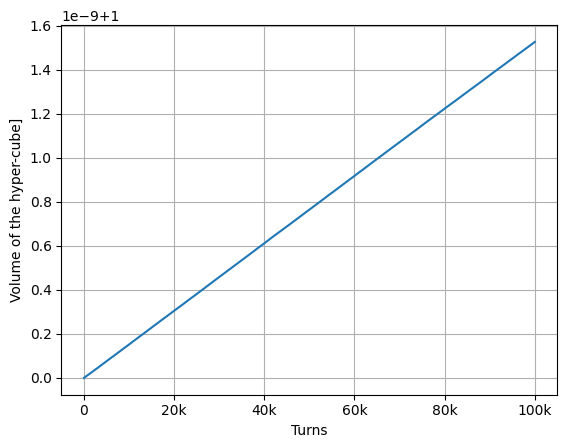

In [27]:
# vertical concatenated array
my_det = []
for turn in range(n_turns):
    V_matrix = np.vstack([line.record_last_track.x[:,turn],
            line.record_last_track.px[:,turn],
            line.record_last_track.y[:,turn],
            line.record_last_track.py[:,turn],
            line.record_last_track.zeta[:,turn],
            line.record_last_track.delta[:,turn],
            ])
    my_det.append(np.linalg.det(V_matrix))

plt.plot(my_det)

plt.xlabel('Turns')
plt.ylabel('Volume of the hyper-cube]')
plt.grid(True)

plt.xticks(np.arange(0, 100001, 20000), ['0', '20k', '40k', '60k', '80k', '100k']);


### The problem of stability

In [28]:
# Create an environment
# switch off the warning for the moment
import warnings
warnings.filterwarnings('ignore')
env = xt.Environment()

env['k1'] = 1
env['k2'] = 1


# Build the simplest stable lattice
line = env.new_line(components=[
    # a quadrupole of length of 1 [m] and k1 equal to 1 [1/m^2]
    env.new('start', xt.Marker), 
    env.new('q1', xt.Quadrupole, length=1, k1='k1'), 
    # a drift of length of 1 [m]
    env.new('drift_1',  xt.Drift, length=1),
    env.new('q2', xt.Quadrupole, length=1, k1='k2'),
    env.new('drift_2',  xt.Drift, length=1),
    env.new('end', xt.Marker), 
])

# Define reference particle
line.particle_ref = xt.Particles(p0c=7e12, mass0=xt.PROTON_MASS_EV)
kf_list = []
kd_list = []
stable_list = []

for ii in range(5000):
    try:
        env['k1'] = np.random.uniform(-1.5,1.5)
        env['k2'] = np.random.uniform(-1.5,1.5)
        kf_list.append(env['k1'])
        kd_list.append(env['k2'])
        stable_list.append(1)
        line.twiss4d()
    except:
        stable_list[-1] = 0


Text(0.5, 1.0, 'Stability diagram: in yellow the (k1,k2) of the stable lattices')

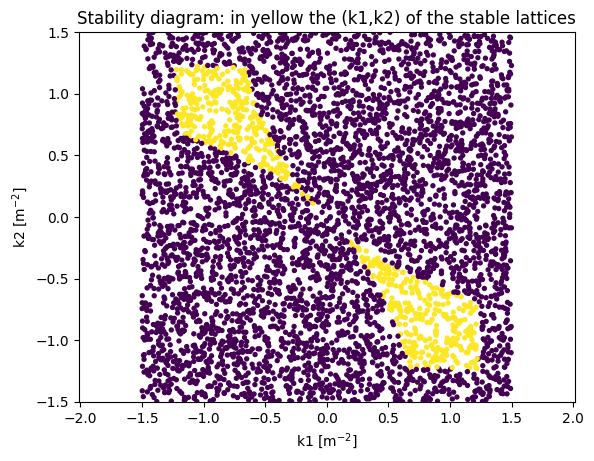

In [29]:
#  scatter plot using kf_list and kf_list and coloring the points according to stable_list
plt.scatter(kf_list, kd_list, c=stable_list, alpha=1, s=8)

plt.axis('equal')
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.xlabel('k1 [m$^{-2}$]')
plt.ylabel('k2 [m$^{-2}$]')
plt.title('Stability diagram: in yellow the (k1,k2) of the stable lattices')

### Beam envelopes

Text(0, 0.5, 'Beam sizes [um]')

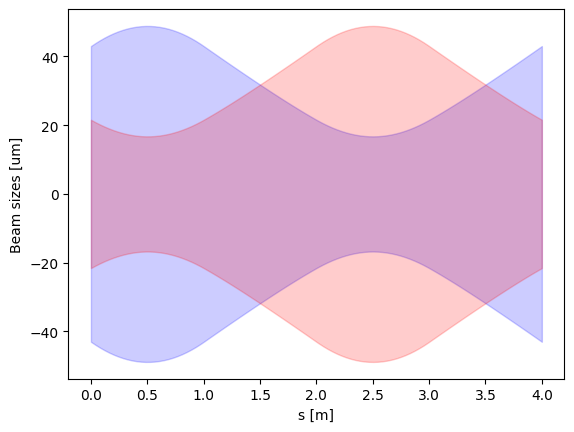

In [30]:
# Transverse normalized emittances
nemitt_x = 2.5e-6
nemitt_y = 2.5e-6

# Longitudinal emittance from energy spread
sigma_pzeta = 2e-4
gemitt_zeta = sigma_pzeta**2 * my_twiss.bets0
# similarly, if the bunch length is known, the emittance can be computed as
# gemitt_zeta = sigma_zeta**2 / tw.bets0

beam_sizes = my_twiss.get_beam_covariance(nemitt_x=nemitt_x,
                                    nemitt_y=nemitt_y,
                                    gemitt_zeta=gemitt_zeta)


# fill region between the two curves
plt.fill_between(beam_sizes['s'], beam_sizes['sigma_x']*1e6, -beam_sizes['sigma_x']*1e6, color='b', alpha=0.2)
plt.fill_between(beam_sizes['s'], beam_sizes['sigma_y']*1e6, -beam_sizes['sigma_y']*1e6, color='r', alpha=0.2)
plt.xlabel('s [m]')
plt.ylabel('Beam sizes [um]')
# 3D plot of the beam sizes sigma_x and sigma_y as a function of s?




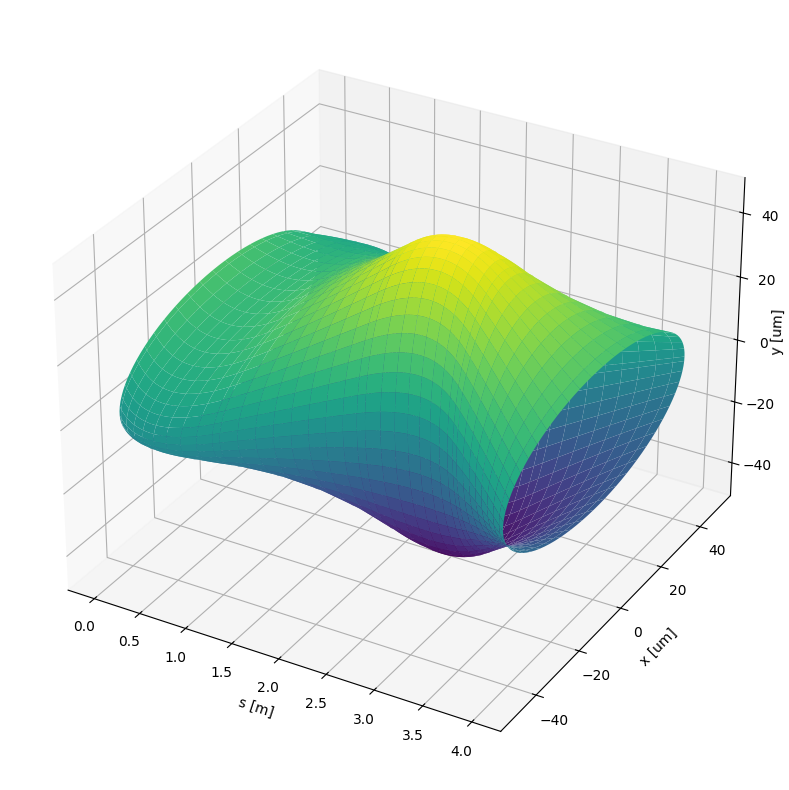

In [31]:

from mpl_toolkits.mplot3d import Axes3D

# Define the range of s
s = beam_sizes.s  # Longitudinal position

# Define sigma_x(s) and sigma_y(s) as functions or arrays
sigma_x = beam_sizes.sigma_x*1e6
sigma_y = beam_sizes.sigma_y*1e6

# Create a meshgrid for theta (angle around the envelope)
theta = np.linspace(0, 2 * np.pi, 100)

# Create the 3D arrays for plotting
S, T = np.meshgrid(s, theta)  # Meshgrid for s and theta

# Parametric equations for the 3D envelope
X = sigma_x * np.cos(T)  # X in the horizontal plane
Y = sigma_y * np.sin(T)  # Y in the vertical plane
Z = S  # Z is the longitudinal axis

# Create the 3D plot
fig = plt.figure(figsize=(15, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface representing the 3D envelope
ax.plot_surface(Z, X, Y, cmap='viridis', alpha=1, shade=True)

# Labels for axes
ax.set_xlabel('s [m]')
ax.set_ylabel('x [um]')
ax.set_zlabel('''y [um]\n\n''')

# Show the plot
plt.show()
